# HanuAi Task 2: EDA, Text Mining and Failure Clustering

**Dataset:** `Hanuai task2 assignment.csv` (1000 warranty / service events, 20 columns)

**What I do in this notebook**
1. Look at the data (types, missing values, duplicates) and clean it
2. Summary stats and plots for the important columns
3. Pull structured tags (components, conditions, fixes, error codes) out of the free-text fields
4. Group the tags into higher level issue categories
5. Trend analysis, then TF-IDF + K-Means clustering to find natural failure groups and likely root causes
6. Export the tagged dataset

Only 5 of the 1000 rows already have the tag columns (`Trigger`, `Failure Component`, etc.) filled in. I use those 5 as a style guide for the tags and fill the rest from the text.

In [1]:
import os, re, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter
from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.cluster import KMeans
from sklearn.decomposition import TruncatedSVD
from sklearn.metrics import silhouette_score

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')
os.makedirs('figures', exist_ok=True)

df = pd.read_csv('Hanuai task2 assignment.csv')
print(df.shape)
df.head(3).T

(1000, 20)


,0,1,2
Event id,D-14801,D-14869,D-14555
Opened date,9/17/2019,7/6/2020,1/9/2020
CAUSAL_VERBATIM,unable to duplicate the concern at this time r...,upon inspection radio screen was found to be b...,Scanned found no codes checked for bulletins f...
CORRECTION_VERBATIM,"waiting for techline engineering response, att...",and ground at radio as stated in service info ...,radio module internal failure
CUSTOMER_VERBATIM,Customer reports that radio and screen is inte...,RADIO IS INOPERABLE CHECK AND ADVISE,CUSTOMER STATES RADIO SCREEN AND ONSTAR KEEPS ...
BUILD_DATE,2019-08-14T00:00:00.000Z,2019-08-16T00:00:00.000Z,2019-08-06T00:00:00.000Z
BUILD_PLANT_DESC,Flint,Fort Wayne,Flint
CAUSAL_CD_DESC,Module/Component-No/Incorrect Communication,Module/Component-Shorted,Module/Component-Worn/Stripped
COMPLAINT_CD_DESC,Audio/Entertainment/Navigation - Other issues,Audio/Entertainment/Navigation - Other issues,Audio/Entertainment/Navigation - Other issues
IN_USE_DATE,2019-09-10T00:00:00.000Z,2020-03-26T00:00:00.000Z,2019-11-29T00:00:00.000Z


## 1. Data assessment

In [2]:
print(df.dtypes)
print()
miss = df.isna().sum()
print(miss[miss > 0])
print()
print('Duplicate rows       :', df.duplicated().sum())
print('Duplicate Event ids  :', df['Event id'].duplicated().sum())
print()
print(df.nunique().sort_values())

Event id                 str
Opened date              str
CAUSAL_VERBATIM          str
CORRECTION_VERBATIM      str
CUSTOMER_VERBATIM        str
BUILD_DATE               str
BUILD_PLANT_DESC         str
CAUSAL_CD_DESC           str
COMPLAINT_CD_DESC        str
IN_USE_DATE              str
MAKE                     str
MODEL                    str
MODLYR                 int64
PLANT                    str
Trigger                  str
Failure Component        str
Failure Condition        str
Additional Context       str
Fix Component            str
Fix Condition            str
dtype: object

CAUSAL_VERBATIM         1
CAUSAL_CD_DESC          3
IN_USE_DATE             1
Trigger               995
Failure Component     995
Failure Condition     995
Additional Context    995
Fix Component         995
Fix Condition         995
dtype: int64

Duplicate rows       : 0
Duplicate Event ids  : 0

MODLYR                    1
Trigger                   2
Fix Condition             2
Additional Context    

Things I notice:
- `MODLYR` has a single value (2020) so it tells us nothing. `MAKE`, `MODEL`, `PLANT` are anonymised names.
- The 6 tag columns are empty for 995 rows. These are what I need to create from text.
- Missing: 1 `CAUSAL_VERBATIM`, 3 `CAUSAL_CD_DESC`, 1 `IN_USE_DATE`. Small, but I still deal with them.
- Many `CAUSAL_VERBATIM` cells contain only spaces or a few characters (the free text looks truncated in places, e.g. words cut off mid sentence).
- Dates are strings in two different formats.

## 2. Cleaning

In [3]:
raw = df.copy()

# --- dates ---
df['Opened date'] = pd.to_datetime(df['Opened date'], format='%m/%d/%Y')
for c in ['BUILD_DATE', 'IN_USE_DATE']:
    df[c] = pd.to_datetime(df[c], utc=True).dt.tz_localize(None).dt.normalize()

# --- text columns: blank / whitespace only -> empty string, collapse spaces ---
text_cols = ['CUSTOMER_VERBATIM', 'CAUSAL_VERBATIM', 'CORRECTION_VERBATIM']
df['causal_was_missing'] = df['CAUSAL_VERBATIM'].isna() | (df['CAUSAL_VERBATIM'].fillna('').str.strip().str.len() < 5)
for c in text_cols:
    df[c] = df[c].fillna('').str.replace(r'\s+', ' ', regex=True).str.strip()

# --- complaint code has a stray leading space on one label, split into area + type ---
df['COMPLAINT_CD_DESC'] = df['COMPLAINT_CD_DESC'].str.strip()
parts = df['COMPLAINT_CD_DESC'].str.split(' - ', n=1, expand=True)
df['COMPLAINT_AREA'], df['COMPLAINT_TYPE'] = parts[0].str.strip(), parts[1].str.strip()

# --- causal code: 3 missing -> 'Unknown' ---
df['CAUSAL_CD_DESC'] = df['CAUSAL_CD_DESC'].fillna('Unknown')
df['CAUSAL_GROUP'] = df['CAUSAL_CD_DESC'].str.split('-', n=1).str[0].str.strip()

# --- IN_USE_DATE: 1 missing. use build date + median build->in-use gap ---
gap = (df['IN_USE_DATE'] - df['BUILD_DATE']).dt.days
median_gap = int(gap.median())
print('median build -> in-service gap (days):', median_gap)
df['in_use_imputed'] = df['IN_USE_DATE'].isna()
df.loc[df['in_use_imputed'], 'IN_USE_DATE'] = df.loc[df['in_use_imputed'], 'BUILD_DATE'] + pd.Timedelta(days=median_gap)

# --- duplicates (exact + same event id) ---
before = len(df)
df = df.drop_duplicates(subset='Event id').drop_duplicates(subset=text_cols + ['BUILD_DATE', 'PLANT']).reset_index(drop=True)
print('rows dropped as duplicates:', before - len(df))

# --- derived numeric columns ---
df['days_build_to_use'] = (df['IN_USE_DATE'] - df['BUILD_DATE']).dt.days
df['days_in_service'] = (df['Opened date'] - df['IN_USE_DATE']).dt.days
# some events are opened BEFORE the recorded in-service date. that cannot be a real time-in-service,
# so I flag them and leave days_in_service empty for those rows instead of keeping negative numbers
df['opened_before_in_use'] = df['days_in_service'] < 0
print('events opened before the in-service date:', df['opened_before_in_use'].sum())
df.loc[df['opened_before_in_use'], 'days_in_service'] = np.nan
print('negative build->use rows     :', (df['days_build_to_use'] < 0).sum())
df['open_month'] = df['Opened date'].dt.to_period('M').dt.to_timestamp()
df[['days_build_to_use', 'days_in_service']].describe()

median build -> in-service gap (days): 91
rows dropped as duplicates: 0
events opened before the in-service date: 76
negative build->use rows     : 0


,days_build_to_use,days_in_service
count,1000.000000,924.000000
mean,121.068000,241.653680
std,99.513367,161.005088
min,1.000000,0.000000
25%,46.000000,106.500000
50%,91.000000,228.000000
75%,164.250000,365.250000
max,596.000000,615.000000


## 3. Summary statistics and distributions

In [4]:
df['cust_len'] = df['CUSTOMER_VERBATIM'].str.len()
df['causal_len'] = df['CAUSAL_VERBATIM'].str.len()
df['corr_len'] = df['CORRECTION_VERBATIM'].str.len()
num = ['days_build_to_use', 'days_in_service', 'cust_len', 'causal_len', 'corr_len']
stats = df[num].agg(['count', 'mean', 'median', 'std', 'min', 'max']).T.round(1)
stats

,count,mean,median,std,min,max
days_build_to_use,1000.0,121.1,91.0,99.5,1.0,596.0
days_in_service,924.0,241.7,228.0,161.0,0.0,615.0
cust_len,1000.0,100.1,78.5,80.2,5.0,794.0
causal_len,1000.0,138.0,75.0,179.7,0.0,1866.0
corr_len,1000.0,176.2,94.0,218.8,8.0,1849.0


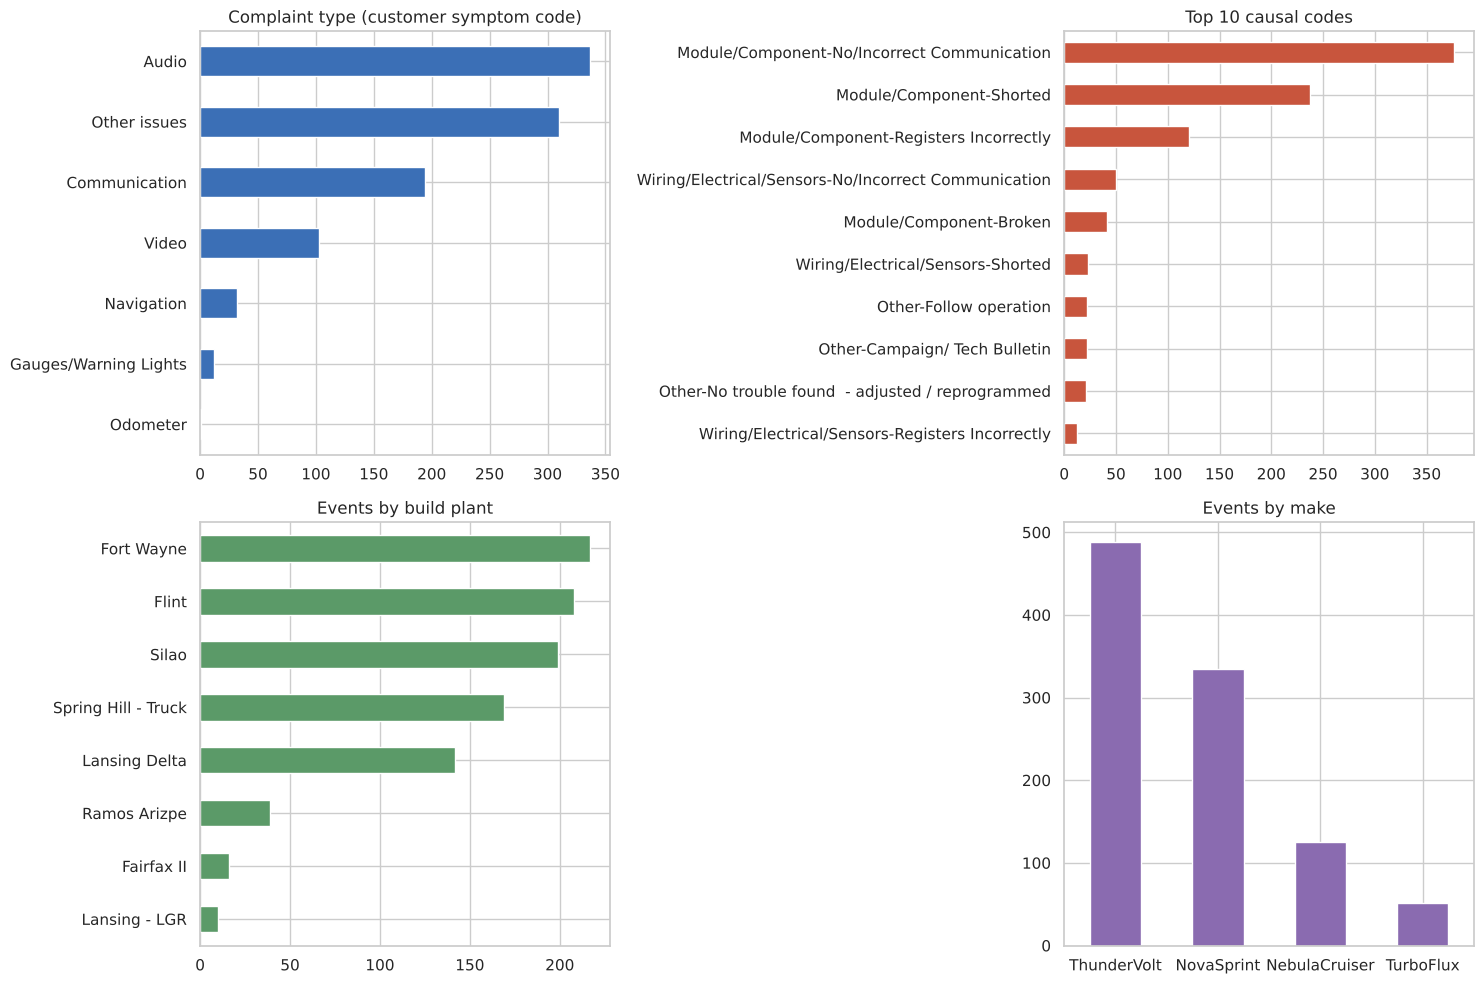

In [5]:
fig, ax = plt.subplots(2, 2, figsize=(15, 10))

df['COMPLAINT_TYPE'].value_counts().sort_values().plot.barh(ax=ax[0, 0], color='#3b6fb6')
ax[0, 0].set_title('Complaint type (customer symptom code)')

df['CAUSAL_CD_DESC'].value_counts().head(10).sort_values().plot.barh(ax=ax[0, 1], color='#c8553d')
ax[0, 1].set_title('Top 10 causal codes')

df['BUILD_PLANT_DESC'].value_counts().sort_values().plot.barh(ax=ax[1, 0], color='#5b9a68')
ax[1, 0].set_title('Events by build plant')

df['MAKE'].value_counts().plot.bar(ax=ax[1, 1], color='#8a6bb0', rot=0)
ax[1, 1].set_title('Events by make')

for a in ax.flat: a.set_ylabel(''); a.set_xlabel('')
plt.tight_layout(); plt.savefig('figures/01_categorical_distributions.png', dpi=130); plt.show()

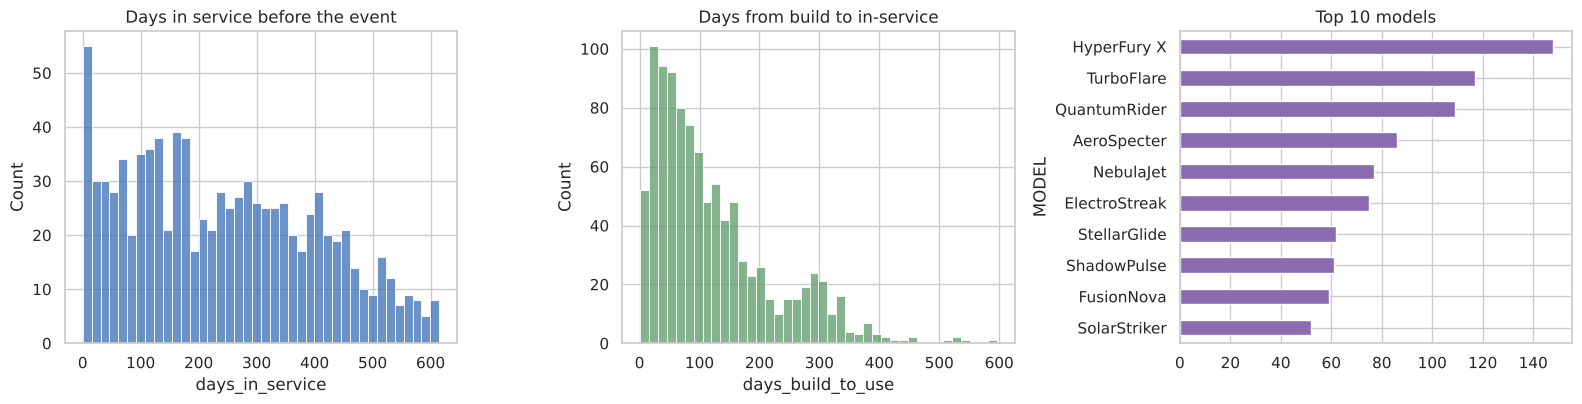

MODEL
HyperFury X      148
TurboFlare       117
QuantumRider     109
AeroSpecter       86
NebulaJet         77
ElectroStreak     75
StellarGlide      62
ShadowPulse       61
FusionNova        59
SolarStriker      52
Name: count, dtype: int64


In [6]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
sns.histplot(df['days_in_service'], bins=40, ax=ax[0], color='#3b6fb6'); ax[0].set_title('Days in service before the event')
sns.histplot(df['days_build_to_use'], bins=40, ax=ax[1], color='#5b9a68'); ax[1].set_title('Days from build to in-service')
df['MODEL'].value_counts().head(10).sort_values().plot.barh(ax=ax[2], color='#8a6bb0'); ax[2].set_title('Top 10 models')
plt.tight_layout(); plt.savefig('figures/02_numeric_distributions.png', dpi=130); plt.show()
print(df['MODEL'].value_counts().head(10))

Takeaways: the problem is overwhelmingly about audio / entertainment (radio, screen). Most causal codes point at a module or component (not at wiring). A big share of events happen within the first year of service, and the same few plants and models show up at the top.

## 4. Text mining and entity tagging

Free-text fields: `CUSTOMER_VERBATIM` (what the customer says), `CAUSAL_VERBATIM` (what the technician found) and `CORRECTION_VERBATIM` (what was done).

Approach: dictionary / regex based entity extraction. I chose this over a transformer NER model because the text is short, full of shop abbreviations (`C/S`, `SPS`, `TAC`, `DTC`), often ALL CAPS and with words glued together (`ANDRADIO`), so a hand built dictionary is easier to check and to explain. Tags are produced per field:

| Output column | Source text | What it captures |
|---|---|---|
| Failure Component | customer text (fallback: causal text) | what part is reported as failing |
| Failure Condition | customer text (fallback: causal text) | the symptom |
| Trigger | customer + causal text | when it happens (cold start, reversing, after update...) |
| Causal Finding | causal text | what the technician found |
| Fix Component | correction text | what was worked on |
| Fix Condition | correction text | what was done to it |
| Additional Context | all text | repeat visit, escalation to TAC / engineering, non-English text |
| DTC Mentioned | technician text | whether a stored diagnostic trouble code is mentioned (True / False) |

In [7]:
def norm(t):
    return re.sub(r'\s+', ' ', str(t).lower()).strip()

NEG = re.compile(r"\b(no|not|none|without|neither|never|nothing|ok|okay|good|within spec)\b[^.;,]{0,22}$")

def hits(text, pattern, check_neg=False):
    # True if pattern is found. optionally ignore matches that look negated ("no corrosion", "wiring ok")
    for m in re.finditer(pattern, text):
        if check_neg and NEG.search(text[max(0, m.start() - 30):m.start()]):
            continue
        return True
    return False

def tag(text, rules, check_neg=False):
    out = [label for label, pat in rules if hits(text, pat, check_neg)]
    return out

# ---------- what is failing (customer side) ----------
COMPONENT_RULES = [
    ('Radio',                r"radio|head ?unit|infotain|stereo|\bhmi\b|\brcm\b|receiver"),
    ('Display',              r"screen|display|monitor|pantalla|\blcd\b"),
    ('Audio/Speakers',       r"speaker|sound|audio|volume|amplifier|\bamp\b|subwoofer|bocina|sonido"),
    ('Satellite Radio',      r"\bxm\b|sirius|satell"),
    ('OnStar/Telematics',    r"onstar|telematic|\btcm\b|\b4g\b|\blte\b|wi-?fi|hotspot|\bvcim\b"),
    ('Bluetooth/Phone',      r"bluetooth|blue tooth|\bphone|carplay|android auto|\bpair"),
    ('USB/AUX Port',         r"\busb\b|\baux\b|charging port"),
    ('Navigation/GPS',       r"navigation|\bnav\b|\bgps\b|\bmaps?\b"),
    ('Camera',               r"camera|backup|back-up|rear ?view|reverse"),
    ('Antenna',              r"antenna"),
    ('Steering Controls',    r"steering (wheel )?(control|button|switch)|\bswc\b"),
    ('Instrument Cluster',   r"cluster|gauge|speedometer|odometer|warning light|\bipc\b"),
    ('Climate Controls',     r"hvac|climate|heater|\ba/c\b"),
    ('Battery/Power',        r"battery|loosing power|losing power|drain|parasitic"),
    ('Wiring/Connector',     r"wiring|harness|connector|\bfuse"),
]

CONDITION_RULES = [
    ('Inoperative',          r"inop|not work|no work|doesn.?t work|does not work|won.?t (turn|power|work|come|start)|not turn(ing)? on|no power|stopped working|quit working|not function|dead|failed|not operat"),
    ('Black Screen',         r"black|blank|\bdark\b|negra|screen (is )?off|goes out"),
    ('No Sound',             r"no sound|no audio|without sound|\bmute|silent|no volume|sin sonido|loss of sound|sound (cuts|goes|drops)|cuts? out"),
    ('Intermittent',         r"intermit|at times|random|sporadic|sometimes|off and on|on and off|comes? and goes?|occasional"),
    ('Freezing/Lock-up',     r"freez|froze|frozen|lock(s|ed)? ?up|\bhangs?\b|stuck|stall"),
    ('Reboot/Reset',         r"reboot|reset|restart|re-?start|cycl|shuts? (off|down|itself)|turns? (off|itself)|powers? (off|down)"),
    ('Noise/Distortion',     r"static|distort|noise|crackl|buzz|\bpop|\bhum\b|whin|squeal|rattl|garbled|scratch"),
    ('Connectivity Failure', r"connect|\bpair|lost com|no com|communicat|\bsync|network|disconnect|drops?"),
    ('No/Poor Reception',    r"no xm|reception|signal|no stations?|no satell"),
    ('Controls Irresponsive',r"unrespons|not respon|no respon|buttons?|touch|grayed|greyed|slow|\blag|delay"),
    ('Source/Station Switching', r"switch|changes? (station|source)|by itself|on its own|changes by itself"),
    ('Software/Update Issue',r"software|update|reprogram|firmware|re-?flash|version"),
    ('Error/Warning Message',r"message|error|warning|prompt|\bfault|\bdtc"),
    ('Internal Fault',       r"internal (fault|failure|short|issue)|internally"),
    ('Malfunction',          r"malfunction|erratic|glitch|acting up|issues?\b|problem|not right|abnormal"),
    ('Electrical (short/drain)', r"\bshort|battery|drain|power loss|loosing power|losing power|blown|voltage"),
]

TRIGGER_RULES = [
    ('When Reversing',        r"revers|backing|back up|backup"),
    ('After Software Update', r"after (the )?(software |sw )?(update|reprogram|flash)|update failed"),
    ('On Start-up',           r"start ?up|start(ed|ing)? (the )?(vehicle|veh|car|engine)|when (he |she |i )?start|on start|ignition on|turn(ed|ing)? (on|the key)|first start"),
    ('Cold/Hot Weather',      r"\bcold\b|\bhot\b|heat|temperature|weather|rain|wet|water"),
    ('While Driving',         r"while driving|when driving|driving|highway|\bbumps?\b|rough road|speed"),
    ('After Battery Event',   r"battery (was )?(dead|disconnect|replace|jump)|jump ?start|boost"),
    ('Phone/USB Connected',   r"phone|usb|bluetooth|carplay|android auto"),
]

CAUSAL_RULES = [
    ('Internal Module Fault',    r"internal (fault|failure|short|issue)|internally|defective|faulty|bad (radio|module|unit|display)|failed (radio|module|unit|display)|module (has )?fail|radio (has )?fail"),
    ('Loss of Communication',    r"lost com|loss of com|no com|loss communication|lost communication|u0\d{3}|u1\d{3}|ethernet|\bmost bus|\blin bus|\bcan bus|data ?link"),
    ('Poor Connection/Terminal', r"poor (connection|contact)|loose|terminal|pin (drag|fit|tension)|connector (was )?(black|burn|melt|corrod|loose|damag)|will not lock|backed out|not (fully )?seated|spread"),
    ('Corrosion/Water Intrusion',r"corros|water|moisture|wet|rust"),
    ('Short/Overload',           r"\bshort|burn|melt|overload|blown fuse|blown"),
    ('Wiring Damage',            r"chafe|pinch|rubb|cut wire|broken wire|damaged wir|wire (was )?(broken|cut|damaged)|harness (was )?(damaged|cut|broken)|rodent"),
    ('Software/Programming',     r"software|reprogram|update|calibrat|firmware|re-?flash|programming|outdated|bulletin|campaign|tech bulletin"),
    ('Could Not Duplicate',      r"unable to duplicate|could not duplicate|cannot duplicate|can.?t duplicate|not duplicate|unable to verify|no problem found|\bnff\b|could not verify|not able to duplicate|working (normally|properly|fine)|operating (normally|properly)"),
    ('Wrong/Incorrect Part',     r"incorrect (component|part|radio)|wrong (part|radio|component)|incorrect version"),
    ('Battery/Voltage',          r"low voltage|battery|voltage drop|parasitic|drain"),
    ('DTC Stored',               r"\bdtc|codes? (found|set|stored)|stored|set in|\b[ubcp][0-9a-f]{4}\b"),
]

FIX_COMPONENT_RULES = [
    ('Radio',               r"radio|head ?unit|infotain|stereo|\brcm\b|\bhmi\b|receiver"),
    ('Display',             r"display|screen|monitor"),
    ('Antenna',             r"antenna"),
    ('Camera',              r"camera"),
    ('Amplifier',           r"amplifier|\bamp\b"),
    ('Speaker',             r"speaker"),
    ('USB',                 r"\busb\b"),
    ('SPS (programming)',   r"\bsps\b|tech ?2|techline connect"),
    ('Telematics/OnStar Module', r"onstar|telematic|\btcm\b|vcim"),
    ('Other Module',        r"\bmodule|\bvcu\b|\bbcm\b|\bvim\b|control unit|\bcpm\b|\bipc\b|cluster"),
    ('Wiring/Connector',    r"wiring|harness|connector|terminal|\bpin\b|cable|ground|splice"),
    ('Battery',             r"battery"),
    ('Fuse',                r"\bfuse"),
]

FIX_CONDITION_RULES = [
    ('Replaced',            r"replac|\br&r\b|\br ?& ?r\b|swapp|installed (new|a new)|new (radio|unit|module|display)|remove[d]? and install"),
    ('Programmed',          r"program|\bsps\b|flash|configur|setup|set up"),
    ('Software Updated',    r"update|software|calibrat|usb (file|software|transfer)"),
    ('Reset',               r"\breset|reboot|re-?start|battery disconnect|disconnect(ed)? battery"),
    ('Repaired',            r"repair|reseat|re-?seat|tighten|cleaned|clean(ed)? (terminal|connector)|resecure|re-?pin|re-?route|secured|lubricat"),
    ('Cleared Codes',       r"clear(ed)? (all )?(codes|dtc)|cleared"),
    ('No Fault Found',      r"unable to duplicate|could not duplicate|cannot duplicate|not duplicate|no problem found|\bnff\b|could not verify|unable to verify|no fault|working (normally|properly|fine)"),
]

CONTEXT_RULES = [
    ('Repeat Visit',               r"returned|came back|customer back|repeat|previous(ly)?|second (visit|time)|recurr|re-?visit|returns? for|prior repair"),
    ('Escalated to TAC/Engineering', r"\btac\b|techline|tech line|engineering"),
    ('Non-English Text',           r"pantalla|sonido|bocina|cliente|radio la |une fois|signal es|\bpas\b|el radio|se pone|negra"),
    ('After Battery Event',        r"battery (was )?(dead|disconnect|died|replace|jump)|jump ?start|boost"),
]
DTC_WORD = r"\bdtcs?\b|trouble codes?|codes? (found|set|stored)|stored (code|dtc)|\b[ubcp][0-9a-f]{4}\b"


ACTION_RE = re.compile(r"replac\w*|install\w*|\br ?& ?r\b|remove[d]? and|reprogram\w*|program\w*|repair\w*|swapp?\w*|updat\w*|flash\w*|re-?seat\w*|tighten\w*|reset|\bsps\b")

def fix_components(corr):
    # only look at the words around a repair verb, so "checked wiring ok" does not count as a fix on the wiring
    found = []
    for m in ACTION_RE.finditer(corr):
        window = corr[max(0, m.start() - 25): m.end() + 45]
        found += tag(window, FIX_COMPONENT_RULES)
    return uniq(found)

def uniq(seq):
    return list(dict.fromkeys(seq))

### Apply the tagging
For `Failure Component` and `Failure Condition` I use the customer's words first. If nothing matches I fall back to the technician's note, so fewer rows end up untagged.

In [8]:
def build_tags(r):
    cust, caus, corr = norm(r['CUSTOMER_VERBATIM']), norm(r['CAUSAL_VERBATIM']), norm(r['CORRECTION_VERBATIM'])

    fc = tag(cust, COMPONENT_RULES) or tag(caus, COMPONENT_RULES, check_neg=True)
    fcond = tag(cust, CONDITION_RULES) or tag(caus, CONDITION_RULES, check_neg=True)
    trig = tag(cust + ' ' + caus, TRIGGER_RULES, check_neg=True) or ['No Additional Functionality']
    cause = tag(caus, CAUSAL_RULES, check_neg=True)
    fixc = fix_components(corr)
    fixd = tag(corr, FIX_CONDITION_RULES) or ['No Repair Action Recorded']
    ctx = tag(cust + ' ' + caus + ' ' + corr, CONTEXT_RULES) or ['No Additional Context']
    dtc = hits(caus + ' ' + corr, DTC_WORD, check_neg=True)
    return pd.Series({
        'Failure Component_new': fc, 'Failure Condition_new': fcond, 'Trigger_new': trig,
        'Causal Finding': cause, 'Fix Component_new': fixc, 'Fix Condition_new': fixd, 'Additional Context_new': ctx, 'DTC Mentioned': dtc,
    })

tags = df.apply(build_tags, axis=1)
df = pd.concat([df, tags], axis=1)

# how many rows ended up with at least one tag?
for c in tags.columns:
    if c == 'DTC Mentioned':
        print(f'{c:24s} True rows  : {df[c].sum():4d} / {len(df)}'); continue
    print(f'{c:24s} tagged rows: {(df[c].str.len() > 0).sum():4d} / {len(df)}')
print()
print('Actual DTC numbers (like U0100) in the text:', df[text_cols].apply(lambda s: s.str.contains(r'\b[UBCP][0-9A-F]{4}\b', regex=True)).any(axis=1).sum(),
      ' -> the code numbers look scrubbed from the verbatims, so I only keep a True/False flag')

Failure Component_new    tagged rows:  991 / 1000
Failure Condition_new    tagged rows:  957 / 1000
Trigger_new              tagged rows: 1000 / 1000
Causal Finding           tagged rows:  584 / 1000
Fix Component_new        tagged rows:  943 / 1000
Fix Condition_new        tagged rows: 1000 / 1000
Additional Context_new   tagged rows: 1000 / 1000
DTC Mentioned            True rows  :  153 / 1000

Actual DTC numbers (like U0100) in the text: 0  -> the code numbers look scrubbed from the verbatims, so I only keep a True/False flag


### Sanity check against the 5 rows that already had tags
These are the only rows with human labels, so I compare them with what my rules produce.

In [9]:
chk = df[df['Failure Component'].notna()][['Event id', 'Failure Component', 'Failure Component_new', 'Failure Condition', 'Failure Condition_new', 'Fix Component', 'Fix Component_new', 'Fix Condition', 'Fix Condition_new']]
pd.set_option('display.max_colwidth', 80, 'display.width', 250)
chk.T

,0,1,2,3,4
Event id,D-14801,D-14869,D-14555,D-14704,D-15142
Failure Component,"['Audio Unit', 'Display']","['Radio', 'Display', 'Radio']","['Display', 'OnStar', 'Radio Module']",['Display'],['Radio']
Failure Component_new,"[Radio, Display]",[Radio],"[Radio, Display, OnStar/Telematics]",[Display],"[Radio, Display, Satellite Radio]"
Failure Condition,"['Controls Irresponsive', 'Black Screen']","['Inoperative', 'Black Screen', 'No Sound']","['Inoperative', 'Inoperative', 'Internal Fault']",['Black Screen'],['Malfunction']
Failure Condition_new,"[Inoperative, Intermittent]",[Inoperative],"[Connectivity Failure, Error/Warning Message]",[Black Screen],"[Connectivity Failure, No/Poor Reception, Error/Warning Message]"
Fix Component,"['Radio', 'SPS']","['Radio', 'USB']",['Radio'],"['Radio', 'USB']",['Radio']
Fix Component_new,"[Radio, SPS (programming), USB, Display]",[Radio],[],[],"[Radio, Antenna, USB]"
Fix Condition,"['Replaced', 'Programmed']","['Replaced', 'Programmed']",['Replaced'],"['Replaced', 'Programmed']",['Replaced']
Fix Condition_new,"[Replaced, Programmed, Software Updated, Reset]","[Replaced, Programmed, Cleared Codes]",[No Repair Action Recorded],[No Repair Action Recorded],"[Replaced, Software Updated]"


In [10]:
# simple overlap score: share of the human tags that my rules also found (loose, names differ a bit)
import ast
def overlap(a, b):
    a = {x.lower() for x in ast.literal_eval(a)}
    b = {x.lower() for x in b}
    if not a: return np.nan
    return sum(any(x in y or y in x for y in b) for x in a) / len(a)

lab = df[df['Failure Component'].notna()]
for h, n in [('Failure Component', 'Failure Component_new'), ('Failure Condition', 'Failure Condition_new'),
             ('Fix Component', 'Fix Component_new'), ('Fix Condition', 'Fix Condition_new')]:
    print(f'{h:20s} recall on the 5 labelled rows: {np.nanmean([overlap(a, b) for a, b in zip(lab[h], lab[n])]):.2f}')

Failure Component    recall on the 5 labelled rows: 0.80
Failure Condition    recall on the 5 labelled rows: 0.27
Fix Component        recall on the 5 labelled rows: 0.50
Fix Condition        recall on the 5 labelled rows: 0.60


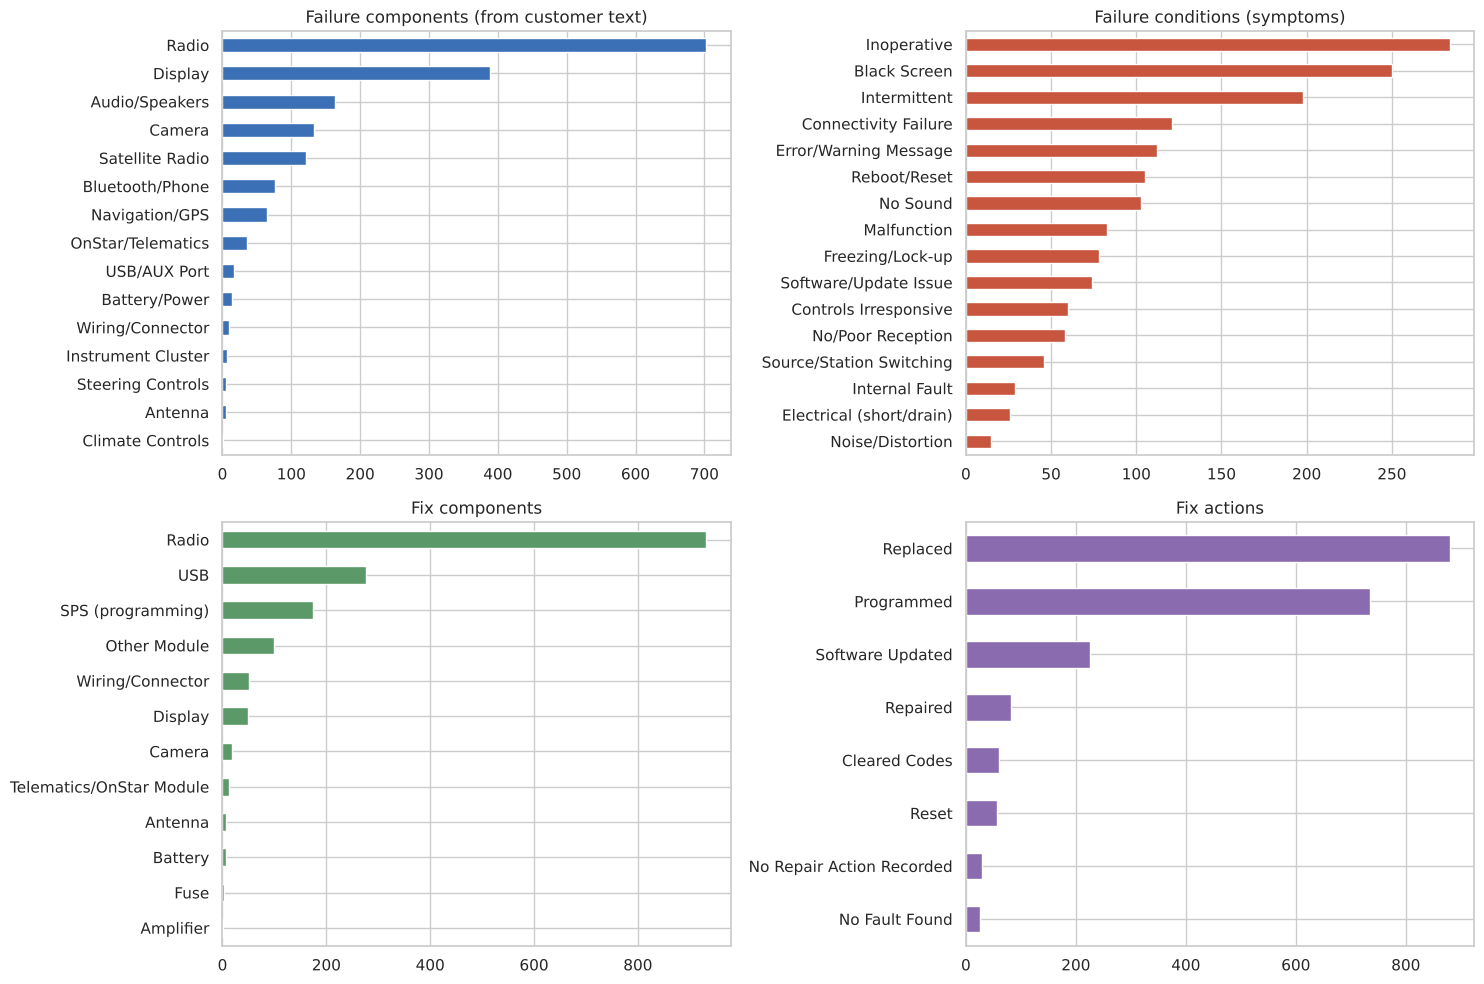

No Additional Context           639
Escalated to TAC/Engineering    301
Repeat Visit                     76
Non-English Text                 14
After Battery Event               9
dtype: int64
Internal Module Fault        251
Software/Programming         207
Loss of Communication        116
DTC Stored                   109
Short/Overload                66
Poor Connection/Terminal      43
Battery/Voltage               28
Could Not Duplicate           22
Wrong/Incorrect Part           4
Corrosion/Water Intrusion      2
Wiring Damage                  1
dtype: int64


In [11]:
def flat(col): return Counter(x for lst in df[col] for x in lst)

fig, ax = plt.subplots(2, 2, figsize=(15, 10))
for a, (col, title, colr) in zip(ax.flat, [
        ('Failure Component_new', 'Failure components (from customer text)', '#3b6fb6'),
        ('Failure Condition_new', 'Failure conditions (symptoms)', '#c8553d'),
        ('Fix Component_new', 'Fix components', '#5b9a68'),
        ('Fix Condition_new', 'Fix actions', '#8a6bb0')]):
    s = pd.Series(flat(col)).sort_values()
    s.plot.barh(ax=a, color=colr); a.set_title(title)
plt.tight_layout(); plt.savefig('figures/03_entity_tags.png', dpi=130); plt.show()

print(pd.Series(flat('Additional Context_new')).sort_values(ascending=False))
print(pd.Series(flat('Causal Finding')).sort_values(ascending=False))

## 5. Issue classification

I group the tags into six higher level categories. It is a scoring rule on the tag columns and the technician text, not a trained model, because there are no labels to train on. Order of rules:

1. **Assembly / Installation Quality**: text says a part was installed wrong, loose, pinched, misrouted, wrong part
2. **No Fault Found**: technician could not duplicate and nothing was replaced
3. Otherwise score **Hardware Component Failure**, **Electrical / Wiring**, **Communication / Connectivity** and **Software / Programming** from the tags. Highest score wins (ties go in that order)
4. If everything scores zero, fall back to the dealer's `CAUSAL_CD_DESC` group

In [12]:
ASSEMBLY_RE = r"incorrect (component|part|radio)|wrong (part|radio|component)|installed incorrect|improper|not (fully )?seated|mis-?rout|pinched|not clipped|misalign|fell off|loose (screw|bolt|trim|panel)|gap|rubbing"

def classify(r):
    allt = norm(r['CUSTOMER_VERBATIM'] + ' ' + r['CAUSAL_VERBATIM'] + ' ' + r['CORRECTION_VERBATIM'])
    causal = r['Causal Finding']; fixd = r['Fix Condition_new']; fixc = r['Fix Component_new']
    cond = r['Failure Condition_new']

    if hits(allt, ASSEMBLY_RE, check_neg=True) or 'Wrong/Incorrect Part' in causal or r['CAUSAL_GROUP'] in ('Fastener', 'Interface (Gasket; Seal; Hose; Weld..)'):
        return 'Assembly / Installation Quality'
    replaced = 'Replaced' in fixd
    if 'Could Not Duplicate' in causal and not replaced:
        return 'No Fault Found'
    if 'No Fault Found' in fixd and not replaced:
        return 'No Fault Found'

    s = {'Hardware Component Failure': 0, 'Electrical / Wiring': 0, 'Communication / Connectivity': 0, 'Software / Programming': 0}
    if replaced and any(x in fixc for x in ['Radio', 'Display', 'Antenna', 'Camera', 'Amplifier', 'Speaker', 'USB', 'Other Module', 'Telematics/OnStar Module']): s['Hardware Component Failure'] += 1
    if 'Internal Module Fault' in causal: s['Hardware Component Failure'] += 2
    if r['CAUSAL_GROUP'] == 'Module/Component' and r['CAUSAL_CD_DESC'].split('-')[-1] in ('Broken', 'Damaged/Cracked', 'Worn/Stripped', 'Shorted'): s['Hardware Component Failure'] += 2

    for k in ['Poor Connection/Terminal', 'Corrosion/Water Intrusion', 'Short/Overload', 'Wiring Damage', 'Battery/Voltage']:
        if k in causal: s['Electrical / Wiring'] += 2
    if 'Wiring/Connector' in fixc or 'Battery' in fixc or 'Fuse' in fixc: s['Electrical / Wiring'] += 1
    if 'Repaired' in fixd: s['Electrical / Wiring'] += 1
    if 'Electrical (short/drain)' in cond: s['Electrical / Wiring'] += 1
    if r['CAUSAL_GROUP'] == 'Wiring/Electrical/Sensors': s['Electrical / Wiring'] += 2

    if 'Loss of Communication' in causal: s['Communication / Connectivity'] += 2
    if 'Connectivity Failure' in cond or 'No/Poor Reception' in cond: s['Communication / Connectivity'] += 1
    if r['CAUSAL_CD_DESC'].endswith('No/Incorrect Communication'): s['Communication / Connectivity'] += 2

    if 'Software/Programming' in causal: s['Software / Programming'] += 2
    if ('Programmed' in fixd or 'Software Updated' in fixd or 'Reset' in fixd) and not replaced: s['Software / Programming'] += 2
    if any(x in cond for x in ['Freezing/Lock-up', 'Reboot/Reset', 'Software/Update Issue']): s['Software / Programming'] += 1
    if r['CAUSAL_CD_DESC'].endswith('Registers Incorrectly'): s['Software / Programming'] += 1
    if r['CAUSAL_CD_DESC'].endswith(('Poor Contact', 'Discharge', 'Loose')): s['Electrical / Wiring'] += 2
    if r['CAUSAL_CD_DESC'].startswith('Other-Campaign') or r['CAUSAL_CD_DESC'].endswith('Incorrect Version') or 'reprogrammed' in r['CAUSAL_CD_DESC']: s['Software / Programming'] += 2

    best = max(s.values())
    if best > 0:
        return [k for k in s if s[k] == best][0]
    # fallback to dealer code
    g = r['CAUSAL_GROUP']
    if g == 'Module/Component': return 'Hardware Component Failure'
    if g == 'Wiring/Electrical/Sensors': return 'Electrical / Wiring'
    if r['CAUSAL_CD_DESC'].startswith('Other-No trouble') or 'Not Duplicated' in r['CAUSAL_CD_DESC']: return 'No Fault Found'
    return 'Unclassified'

df['Issue Category'] = df.apply(classify, axis=1)
cat_counts = df['Issue Category'].value_counts()
print(cat_counts)
print((cat_counts / len(df) * 100).round(1))

Issue Category
Hardware Component Failure         463
Communication / Connectivity       280
Software / Programming             141
Electrical / Wiring                 97
Assembly / Installation Quality     13
No Fault Found                       5
Unclassified                         1
Name: count, dtype: int64
Issue Category
Hardware Component Failure         46.3
Communication / Connectivity       28.0
Software / Programming             14.1
Electrical / Wiring                 9.7
Assembly / Installation Quality     1.3
No Fault Found                      0.5
Unclassified                        0.1
Name: count, dtype: float64


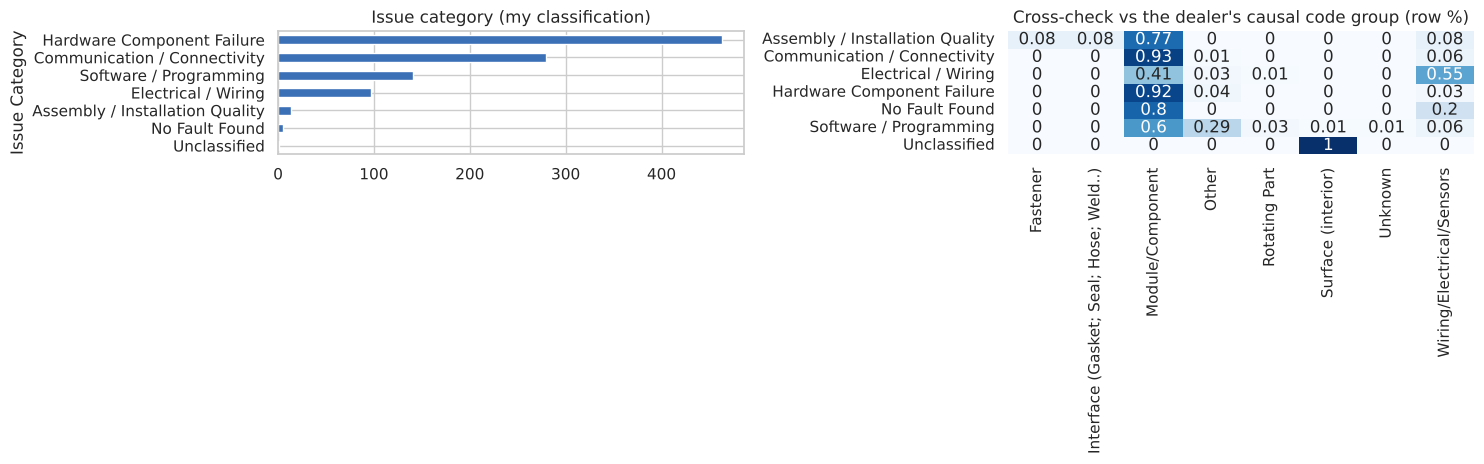

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4.8))
cat_counts.sort_values().plot.barh(ax=ax[0], color='#3b6fb6'); ax[0].set_title('Issue category (my classification)')
ct = pd.crosstab(df['Issue Category'], df['CAUSAL_GROUP'], normalize='index').round(2)
sns.heatmap(ct, annot=True, cmap='Blues', cbar=False, ax=ax[1]); ax[1].set_title("Cross-check vs the dealer's causal code group (row %)")
ax[1].set_ylabel(''); ax[1].set_xlabel('')
plt.tight_layout(); plt.savefig('figures/04_issue_categories.png', dpi=130); plt.show()

Caution: this cross-check is not independent, because I used `CAUSAL_CD_DESC` as one of the scoring inputs. It only shows that my categories are not contradicting the dealer's coding. Hardware is the biggest bucket because replacing the radio is the standard repair, so it shows up in almost every row.

## 6. Trends and patterns

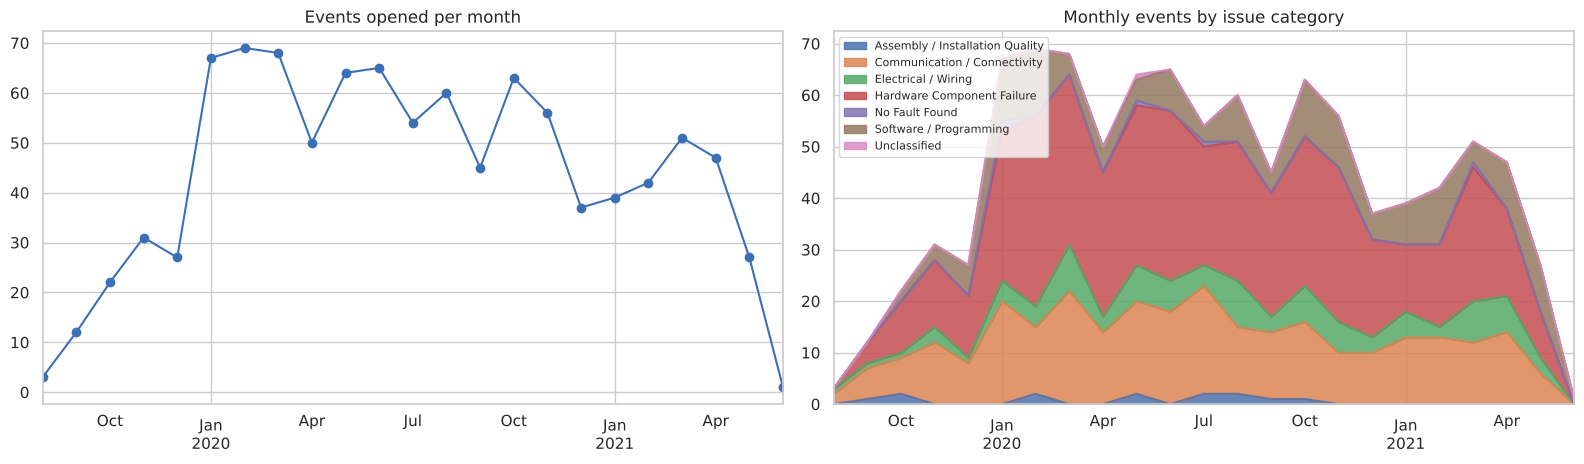

count    23.0
mean     43.5
std      20.7
min       1.0
25%      29.0
50%      47.0
75%      61.5
max      69.0
dtype: float64
peak month: 2020-02 69


In [14]:
monthly = df.groupby('open_month').size()
by_cat = df.pivot_table(index='open_month', columns='Issue Category', values='Event id', aggfunc='count').fillna(0)

fig, ax = plt.subplots(1, 2, figsize=(16, 4.8))
monthly.plot(ax=ax[0], marker='o', color='#3b6fb6'); ax[0].set_title('Events opened per month'); ax[0].set_xlabel('')
by_cat.plot.area(ax=ax[1], stacked=True, alpha=.85); ax[1].set_title('Monthly events by issue category'); ax[1].set_xlabel('')
ax[1].legend(fontsize=8, loc='upper left')
plt.tight_layout(); plt.savefig('figures/05_monthly_trend.png', dpi=130); plt.show()
print(monthly.describe().round(1))
print('peak month:', monthly.idxmax().strftime('%Y-%m'), monthly.max())

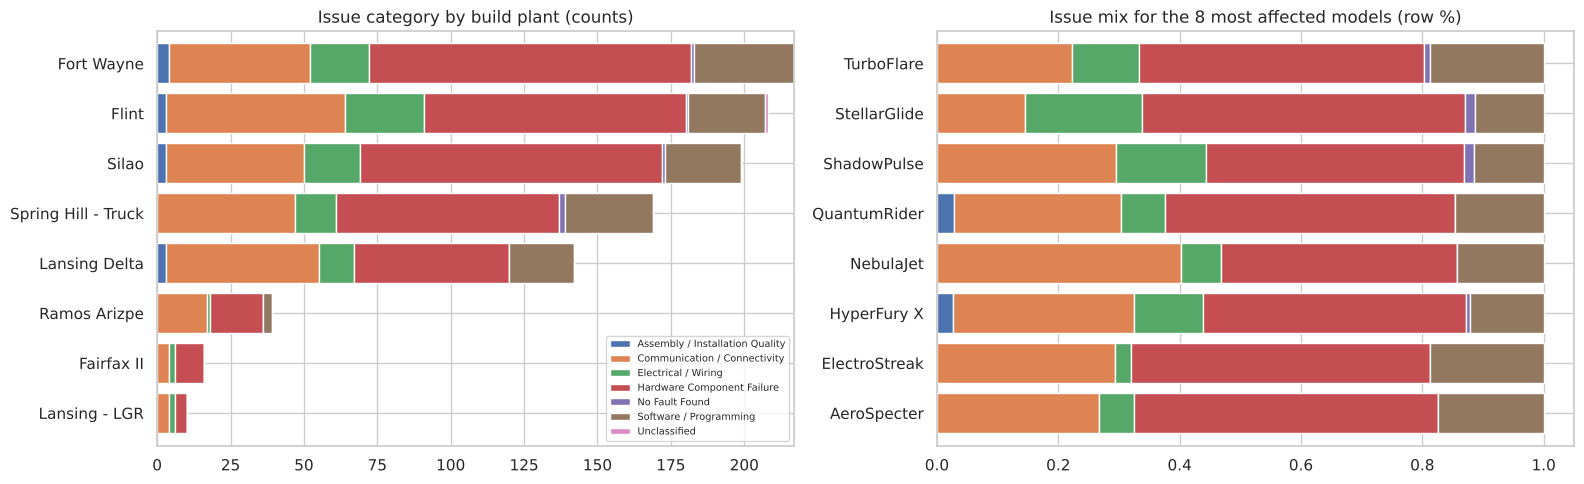

In [15]:
fig, ax = plt.subplots(1, 2, figsize=(16, 5))
pc = pd.crosstab(df['BUILD_PLANT_DESC'], df['Issue Category'])
pc.loc[pc.sum(axis=1).sort_values().index].plot.barh(stacked=True, ax=ax[0], width=.8); ax[0].set_title('Issue category by build plant (counts)'); ax[0].set_ylabel('')
ax[0].legend(fontsize=7)
top_models = df['MODEL'].value_counts().head(8).index
mc = pd.crosstab(df[df['MODEL'].isin(top_models)]['MODEL'], df['Issue Category'], normalize='index')
mc.plot.barh(stacked=True, ax=ax[1], width=.8, legend=False); ax[1].set_title('Issue mix for the 8 most affected models (row %)'); ax[1].set_ylabel('')
plt.tight_layout(); plt.savefig('figures/06_plant_model.png', dpi=130); plt.show()

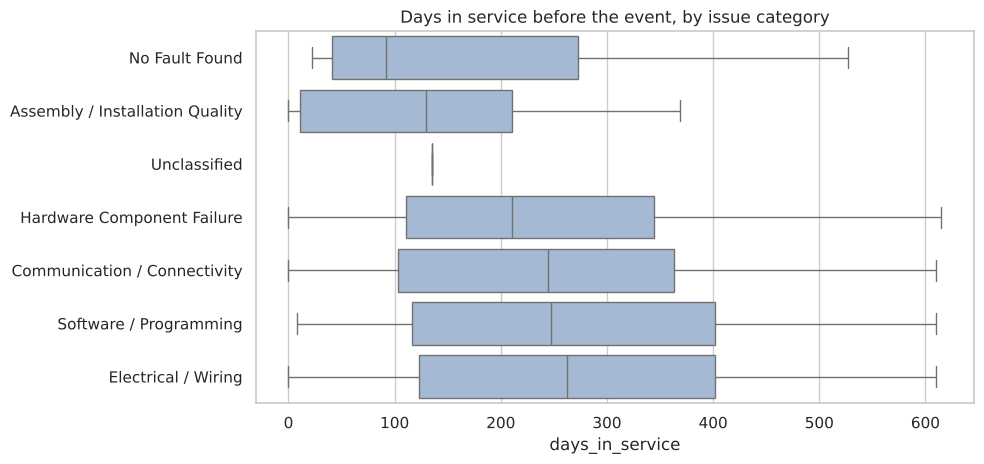

                                 count  median   mean
Issue Category                                       
Assembly / Installation Quality     13   130.0  144.0
Communication / Connectivity       250   244.0  240.0
Electrical / Wiring                 91   262.0  265.0
Hardware Component Failure         429   211.0  235.0
No Fault Found                       5    92.0  191.0
Software / Programming             135   247.0  263.0
Unclassified                         1   135.0  135.0

share of events within 90 / 180 / 365 days of in-service date: [np.float64(0.21), np.float64(0.43), np.float64(0.75)]


In [16]:
fig, ax = plt.subplots(figsize=(10, 4.8))
order = df.groupby('Issue Category')['days_in_service'].median().sort_values().index
sns.boxplot(data=df, y='Issue Category', x='days_in_service', order=order, ax=ax, color='#9db8dd', showfliers=False)
ax.set_title('Days in service before the event, by issue category'); ax.set_ylabel('')
plt.tight_layout(); plt.savefig('figures/07_days_in_service.png', dpi=130); plt.show()
print(df.groupby('Issue Category')['days_in_service'].agg(['count', 'median', 'mean']).round(0))
print()
print('share of events within 90 / 180 / 365 days of in-service date:',
      [(df['days_in_service'].dropna() <= d).mean().round(2) for d in (90, 180, 365)])

In [17]:
# top recurring (component, condition) pairs
pairs = Counter()
for fc, fcond in zip(df['Failure Component_new'], df['Failure Condition_new']):
    for a in fc[:2]:
        for b in fcond[:2]:
            pairs[(a, b)] += 1
top_pairs = pd.DataFrame([(a, b, n) for (a, b), n in pairs.most_common(12)], columns=['Component', 'Condition', 'Events'])
top_pairs

,Component,Condition,Events
0,Display,Black Screen,200
1,Radio,Inoperative,191
2,Radio,Black Screen,187
3,Radio,Intermittent,128
4,Display,Inoperative,100
5,Radio,No Sound,88
6,Radio,Reboot/Reset,68
7,Display,Intermittent,64
8,Radio,Connectivity Failure,61
9,Radio,Freezing/Lock-up,56


## 7. Clustering (TF-IDF + K-Means)

I join the three text fields, clean them, and cluster. I drop shop boilerplate ("customer states", "check and advise", ...) so it does not dominate the clusters, and I also remove anything that looks like a number.

In [18]:
BOILER = {'customer', 'cust', 'states', 'state', 'stated', 'cs', 'check', 'advise', 'advice', 'advsie', 'concern', 'verified', 'verify',
          'inspect', 'found', 'checked', 'tech', 'technician', 'vehicle', 'veh', 'vin', 'performed', 'per', 'tac', 'case', 'sold',
          'hours', 'hour', 'diag', 'diagnostic', 'diagnosis', 'op', 'code', 'labor', 'ok', 'na', 'also', 'told', 'asked', 'wo', 'wcc', 'gds'}
stop = list(ENGLISH_STOP_WORDS | BOILER)

def prep(t):
    t = norm(t)
    t = re.sub(r'[^a-z\s]', ' ', t)
    return re.sub(r'\s+', ' ', t).strip()

df['text_all'] = (df['CUSTOMER_VERBATIM'] + ' ' + df['CAUSAL_VERBATIM'] + ' ' + df['CORRECTION_VERBATIM']).map(prep)

vec = TfidfVectorizer(stop_words=stop, ngram_range=(1, 2), min_df=8, max_df=0.5, sublinear_tf=True)
X = vec.fit_transform(df['text_all'])
terms = np.array(vec.get_feature_names_out())
print('TF-IDF matrix:', X.shape)

TF-IDF matrix: (1000, 894)


    k  silhouette   inertia
0   4      0.0203  925.5473
1   5      0.0231  917.6731
2   6      0.0305  910.5996
3   7      0.0313  903.7106
4   8      0.0338  899.1162
5   9      0.0351  894.6006
6  10      0.0351  889.8172


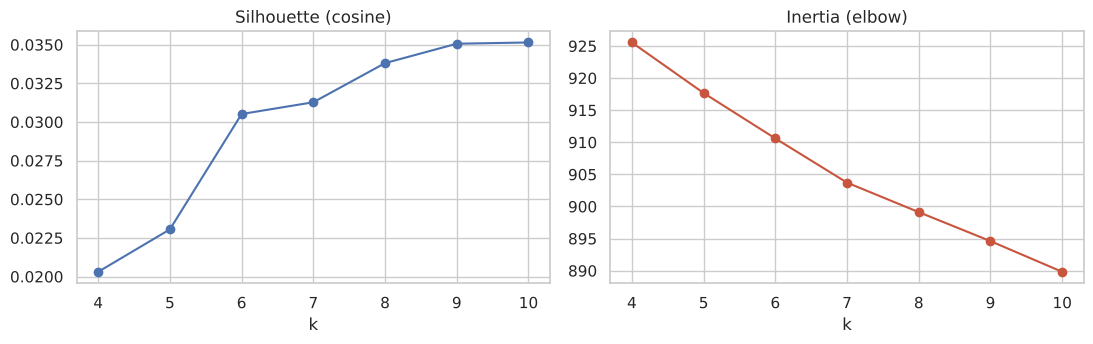

In [19]:
# pick k with silhouette score (cosine) + a look at the cluster terms
res = []
for k in range(4, 11):
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X)
    res.append((k, silhouette_score(X, km.labels_, metric='cosine', sample_size=1000, random_state=42), km.inertia_))
res = pd.DataFrame(res, columns=['k', 'silhouette', 'inertia'])
print(res.round(4))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].plot(res.k, res.silhouette, marker='o'); ax[0].set_title('Silhouette (cosine)'); ax[0].set_xlabel('k')
ax[1].plot(res.k, res.inertia, marker='o', color='#c8553d'); ax[1].set_title('Inertia (elbow)'); ax[1].set_xlabel('k')
plt.tight_layout(); plt.savefig('figures/08_choose_k.png', dpi=130); plt.show()

In [20]:
K = 7
km = KMeans(n_clusters=K, n_init=20, random_state=42).fit(X)
df['cluster'] = km.labels_

order_centroids = km.cluster_centers_.argsort()[:, ::-1]
for c in range(K):
    n = (df['cluster'] == c).sum()
    print(f'--- cluster {c}  (n={n}, {n/len(df):.0%})')
    print('   top terms:', ', '.join(terms[order_centroids[c, :14]]))
    print('   top issue category:', df.loc[df.cluster == c, 'Issue Category'].value_counts().head(2).to_dict())

--- cluster 0  (n=85, 8%)
   top terms: camera, rear, camera inop, backup, backup camera, coax, cable, video, rear camera, view, inop, view camera, rear view, reverse
   top issue category: {'Hardware Component Failure': 38, 'Communication / Connectivity': 22}
--- cluster 1  (n=269, 27%)
   top terms: module, power, communication, ground, programmed, tested, replaced radio, screen, radio module, communication radio, internal, test, circuits, power ground
   top issue category: {'Hardware Component Failure': 123, 'Communication / Connectivity': 91}
--- cluster 2  (n=122, 12%)
   top terms: xm, xm radio, signal, programmed, replaced radio, stations, antenna, replace, internal, replace radio, play, channel, station, change
   top issue category: {'Hardware Component Failure': 59, 'Communication / Connectivity': 40}
--- cluster 3  (n=58, 6%)
   top terms: internal fault, fault, fault radio, internal, scan, replace radio, scan codes, replace, codes, radio scan, radio internal, inop, program

In [21]:
# look at a few raw examples per cluster so the labels are not just guesses from keywords
pd.set_option('display.max_colwidth', 200)
for c in range(K):
    print(f'\n=== cluster {c}')
    for t in df[df.cluster == c].sample(3, random_state=3)['CUSTOMER_VERBATIM']:
        print('  -', t[:170])


=== cluster 0
  - Customer states back up camera give a warning signal to service
  - BACKUP CAMERA IS INOP
  - CUSTOMER STATES WHEN PUTTING INTO REVERESE THERE IS NO BACK UP CAMERA-TWO ICONS SHOW UP ON THE DISPLAY STAYED THAT WAY AFTERPUTTINGINTO DRIVE UNTIL VEHICLE WAS PUT BACK I

=== cluster 1
  - CUSTOMER STATES THAT RADIO WILL NOT POWER UP
  - Audio Entertainment Navigation Video
  - CUSTOMER STATES RADIO STAYS ON

=== cluster 2
  - Customer states radio is still cutting out while playing music. On a cold start music will play for a min and cut right after.
  - customer states the radio quits while driving - turn station or hurn off then back on will start working
  - ( ) REPAIR FOR LOSS OF RADIO SIGNAL AND SOUND

=== cluster 3
  - xm radio drops stations
  - C/S RADIO SCREEN WILL GO BLANK SCREEN, UNABLE TO HEAR ANY AUDIO, WHEN IN REVERSE, ABLE TO SEE REVERSE CAMERA. ADVISE?sop
  - AFTER REPALCING RADIO FOUND CONN FOLDED OVER

=== cluster 4
  - C/S RADIO INT BLACKS OUT AND NO SOU

### Naming the clusters
I read the top terms and the raw examples above and named each cluster by hand. These names are my interpretation, not something the algorithm produces.

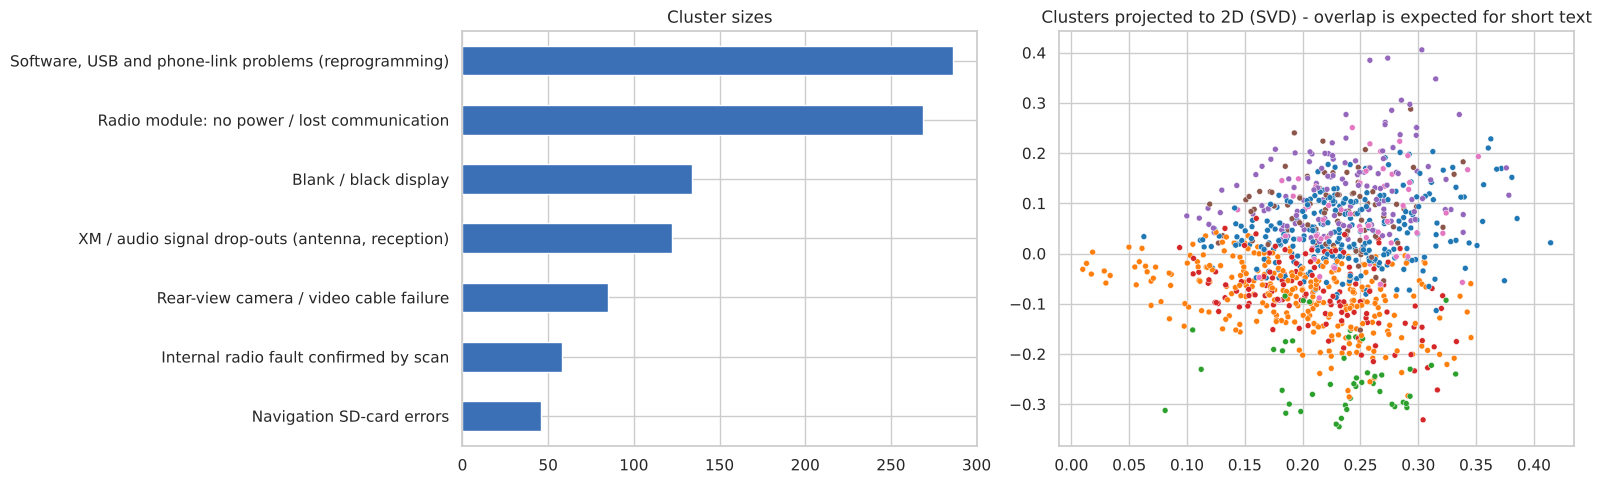

Cluster
Software, USB and phone-link problems (reprogramming)    286
Radio module: no power / lost communication              269
Blank / black display                                    134
XM / audio signal drop-outs (antenna, reception)         122
Rear-view camera / video cable failure                    85
Internal radio fault confirmed by scan                    58
Navigation SD-card errors                                 46
Name: count, dtype: int64

In [22]:
cluster_names = {
    0: 'Rear-view camera / video cable failure',
    1: 'Radio module: no power / lost communication',
    2: 'XM / audio signal drop-outs (antenna, reception)',
    3: 'Internal radio fault confirmed by scan',
    4: 'Software, USB and phone-link problems (reprogramming)',
    5: 'Navigation SD-card errors',
    6: 'Blank / black display',
}
df['Cluster'] = df['cluster'].map(cluster_names)

size = df['Cluster'].value_counts()
fig, ax = plt.subplots(1, 2, figsize=(16, 5))
size.sort_values().plot.barh(ax=ax[0], color='#3b6fb6'); ax[0].set_title('Cluster sizes'); ax[0].set_ylabel('')
svd = TruncatedSVD(n_components=2, random_state=42).fit_transform(X)
sns.scatterplot(x=svd[:, 0], y=svd[:, 1], hue=df['Cluster'], s=18, ax=ax[1], palette='tab10', legend=False)
ax[1].set_title('Clusters projected to 2D (SVD) - overlap is expected for short text')
plt.tight_layout(); plt.savefig('figures/09_clusters.png', dpi=130); plt.show()
size

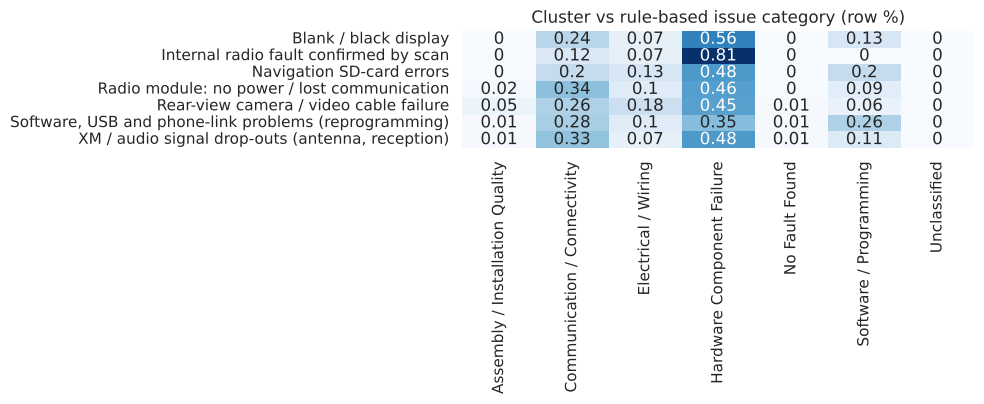

In [23]:
ct = pd.crosstab(df['Cluster'], df['Issue Category'], normalize='index').round(2)
plt.figure(figsize=(10, 4.2)); sns.heatmap(ct, annot=True, cmap='Blues', cbar=False)
plt.title('Cluster vs rule-based issue category (row %)'); plt.ylabel(''); plt.xlabel('')
plt.tight_layout(); plt.savefig('figures/10_cluster_vs_category.png', dpi=130); plt.show()

## 8. Root cause view per cluster

In [24]:
def top_of(series_of_lists, n=2):
    return ', '.join(k for k, _ in Counter(x for l in series_of_lists for x in l).most_common(n))

rows = []
overall_plant = df['BUILD_PLANT_DESC'].value_counts(normalize=True)
for c in sorted(cluster_names):
    d = df[df.cluster == c]
    plant_share = d['BUILD_PLANT_DESC'].value_counts(normalize=True)
    lift = (plant_share / overall_plant).dropna().sort_values(ascending=False)
    rows.append({
        'Cluster': cluster_names[c],
        'Events': len(d), 'Share %': round(len(d) / len(df) * 100, 1),
        'Top terms': ', '.join(terms[order_centroids[c, :6]]),
        'Top failure condition': top_of(d['Failure Condition_new'], 2),
        'Top fix': top_of(d['Fix Condition_new'].map(lambda l: [x for x in l if x != 'No Repair Action Recorded']), 2),
        'Median days in service': d['days_in_service'].median(),
        'Dominant issue category': d['Issue Category'].value_counts().index[0],
        'Plant with highest lift': f'{lift.index[0]} ({lift.iloc[0]:.2f}x)' if len(lift) else '',
    })
root = pd.DataFrame(rows)
pd.set_option('display.max_colwidth', 60, 'display.width', 250)
root

,Cluster,Events,Share %,Top terms,Top failure condition,Top fix,Median days in service,Dominant issue category,Plant with highest lift
0,Rear-view camera / video cable failure,85,8.5,"camera, rear, camera inop, backup, backup camera, coax","Inoperative, Intermittent","Replaced, Programmed",238.0,Hardware Component Failure,Lansing - LGR (2.35x)
1,Radio module: no power / lost communication,269,26.9,"module, power, communication, ground, programmed, tested","Inoperative, Black Screen","Replaced, Programmed",239.0,Hardware Component Failure,Fairfax II (1.63x)
2,"XM / audio signal drop-outs (antenna, reception)",122,12.2,"xm, xm radio, signal, programmed, replaced radio, stations","Inoperative, No/Poor Reception","Replaced, Programmed",160.0,Hardware Component Failure,Lansing - LGR (2.46x)
3,Internal radio fault confirmed by scan,58,5.8,"internal fault, fault, fault radio, internal, scan, repl...","Inoperative, Black Screen","Replaced, Programmed",191.0,Hardware Component Failure,Fairfax II (2.16x)
4,"Software, USB and phone-link problems (reprogramming)",286,28.6,"usb, update, program, replace, phone, replaced radio","Connectivity Failure, Inoperative","Replaced, Programmed",231.0,Hardware Component Failure,Flint (1.04x)
5,Navigation SD-card errors,46,4.6,"card, sd, sd card, error, navigation, nav","Error/Warning Message, Inoperative","Replaced, Programmed",271.0,Hardware Component Failure,Silao (1.53x)
6,Blank / black display,134,13.4,"screen, radio screen, blank, goes, display, screen goes","Black Screen, Intermittent","Replaced, Programmed",259.5,Hardware Component Failure,Ramos Arizpe (1.15x)


In [25]:
# how often is the radio replaced, and how often is replacement the only action?
replaced = df['Fix Condition_new'].map(lambda l: 'Replaced' in l)
prog_only = df['Fix Condition_new'].map(lambda l: ('Programmed' in l or 'Software Updated' in l) and 'Replaced' not in l)
radio_repl = replaced & df['Fix Component_new'].map(lambda l: 'Radio' in l)
print(f'events where something was replaced : {replaced.mean():.1%}')
print(f'events where the radio was replaced : {radio_repl.mean():.1%}')
print(f'events fixed by programming/update without a replacement: {prog_only.mean():.1%}')
print(f'events escalated to TAC / engineering: {df["Additional Context_new"].map(lambda l: "Escalated to TAC/Engineering" in l).mean():.1%}')
print(f'events that look like repeat visits  : {df["Additional Context_new"].map(lambda l: "Repeat Visit" in l).mean():.1%}')

events where something was replaced : 88.0%
events where the radio was replaced : 86.0%
events fixed by programming/update without a replacement: 8.5%
events escalated to TAC / engineering: 30.1%
events that look like repeat visits  : 7.6%


## 9. Export the tagged dataset

In [26]:
out = df.copy()
human = raw['Failure Component'].notna()
out['human_tagged_row'] = human.values[:len(out)] if len(out) == len(raw) else False

# the six original tag columns are filled for every row now (originals kept for the 5 labelled rows)
for old, new in [('Trigger', 'Trigger_new'), ('Failure Component', 'Failure Component_new'), ('Failure Condition', 'Failure Condition_new'),
                 ('Additional Context', 'Additional Context_new'), ('Fix Component', 'Fix Component_new'), ('Fix Condition', 'Fix Condition_new')]:
    out[old + ' (original)'] = raw[old].values
    out[old] = out[new].map(lambda l: str(list(l)))

out['Causal Finding'] = out['Causal Finding'].map(lambda l: str(list(l)))
out['Opened date'] = out['Opened date'].dt.strftime('%Y-%m-%d')
for c in ['BUILD_DATE', 'IN_USE_DATE']:
    out[c] = out[c].dt.strftime('%Y-%m-%d')

keep = ['Event id', 'Opened date', 'CUSTOMER_VERBATIM', 'CAUSAL_VERBATIM', 'CORRECTION_VERBATIM', 'BUILD_DATE', 'BUILD_PLANT_DESC',
        'CAUSAL_CD_DESC', 'COMPLAINT_CD_DESC', 'IN_USE_DATE', 'MAKE', 'MODEL', 'MODLYR', 'PLANT', 'days_in_service', 'opened_before_in_use',
        'in_use_imputed', 'causal_was_missing',
        'Trigger', 'Failure Component', 'Failure Condition', 'Additional Context', 'Fix Component', 'Fix Condition',
        'Causal Finding', 'DTC Mentioned', 'Issue Category', 'cluster', 'Cluster', 'human_tagged_row']
out = out[keep].rename(columns={'cluster': 'Cluster ID'})
out.to_csv('Hanuai_task2_tagged.csv', index=False, encoding='utf-8')
out.to_excel('Hanuai_task2_tagged.xlsx', index=False)
print(out.shape)
out[['Event id', 'Failure Component', 'Failure Condition', 'Fix Component', 'Fix Condition', 'Issue Category', 'Cluster']].head(8)

(1000, 30)


,Event id,Failure Component,Failure Condition,Fix Component,Fix Condition,Issue Category,Cluster
0,D-14801,"['Radio', 'Display']","['Inoperative', 'Intermittent']","['Radio', 'SPS (programming)', 'USB', 'Display']","['Replaced', 'Programmed', 'Software Updated', 'Reset']",Communication / Connectivity,Radio module: no power / lost communication
1,D-14869,['Radio'],['Inoperative'],['Radio'],"['Replaced', 'Programmed', 'Cleared Codes']",Electrical / Wiring,Radio module: no power / lost communication
2,D-14555,"['Radio', 'Display', 'OnStar/Telematics']","['Connectivity Failure', 'Error/Warning Message']",[],['No Repair Action Recorded'],No Fault Found,"Software, USB and phone-link problems (reprogramming)"
3,D-14704,['Display'],['Black Screen'],[],['No Repair Action Recorded'],Communication / Connectivity,"Software, USB and phone-link problems (reprogramming)"
4,D-15142,"['Radio', 'Display', 'Satellite Radio']","['Connectivity Failure', 'No/Poor Reception', 'Error/War...","['Radio', 'Antenna', 'USB']","['Replaced', 'Software Updated']",Hardware Component Failure,"Software, USB and phone-link problems (reprogramming)"
5,D-15149,['Radio'],[],"['Radio', 'USB', 'Wiring/Connector']","['Replaced', 'Programmed', 'Reset', 'Cleared Codes']",Electrical / Wiring,Navigation SD-card errors
6,D-14666,"['Radio', 'Display', 'Audio/Speakers']","['Inoperative', 'No Sound', 'Reboot/Reset']","['Radio', 'SPS (programming)']","['Replaced', 'Programmed', 'Repaired', 'Cleared Codes']",Hardware Component Failure,Radio module: no power / lost communication
7,D-14857,"['Radio', 'Display', 'Camera']","['Inoperative', 'Black Screen', 'Intermittent']",['Radio'],"['Replaced', 'Programmed', 'Cleared Codes']",Communication / Connectivity,"Software, USB and phone-link problems (reprogramming)"


## 10. Summary and limitations

**What the data says**
- Almost every event is a radio / display problem. The same pair of symptoms (black screen, inoperative) dominates.
- The usual repair is replacing the radio and programming the new one. A good share of events are also escalated to TAC / engineering.
- The rule-based categories and the clusters only partly line up. Clusters describe *what the customer sees* (camera, XM signal, blank screen, SD card), the categories describe *what the technician concluded* (hardware, communication, software, wiring).

**Limitations (being honest about them)**
- Tags come from keyword rules. They catch the common wording but will miss odd phrasing, other languages (a few Spanish and French rows) and truncated notes.
- The DTC code numbers are not in the text, so I cannot do an error-code analysis.
- Silhouette scores are low (about 0.03). Short, noisy text with shared vocabulary ("radio", "replace") overlaps a lot, so clusters are a guide to themes, not hard boundaries.
- There is no production volume per plant or model, so plant and model counts are raw counts, not failure rates.
- 76 events were opened before the in-service date, which is a data quality issue worth checking at the source.

**Next steps if I had more time**: sentence-embedding model + BERTopic, a small hand-labelled set to measure tagging accuracy, and a time-to-failure (survival) view by plant and build week.